In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("engineered_data.csv")

--- Property Price Distribution Statistics (in Lakhs) ---
count    250000.000000
mean        254.586854
std         141.349921
min          10.000000
25%         132.550000
50%         253.870000
75%         376.880000
max         500.000000
Name: Price_in_Lakhs, dtype: float64
Skewness: 0.01


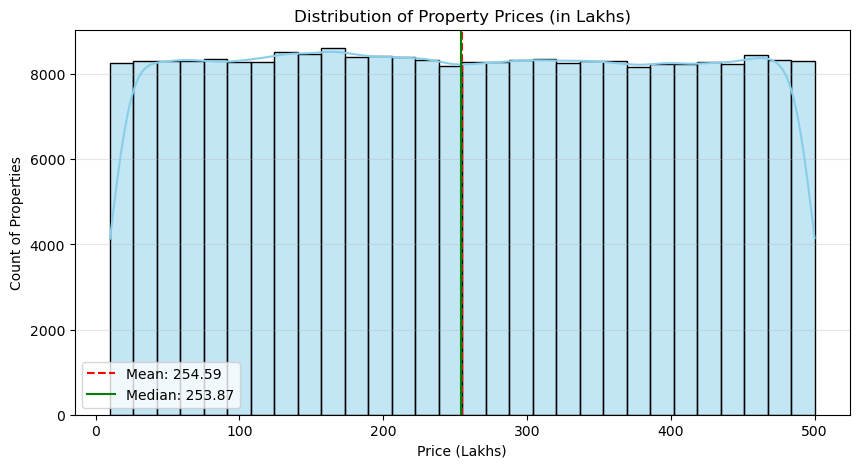

In [4]:
#What is the distribution of property prices?

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate Descriptive Statistics
price_stats = df['Price_in_Lakhs'].describe()
print("--- Property Price Distribution Statistics (in Lakhs) ---")
print(price_stats)
print(f"Skewness: {df['Price_in_Lakhs'].skew():.2f}")

# 2. Plot the Distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Price_in_Lakhs', kde=True, bins=30, color='skyblue')

# Add lines for mean and median to see skewness
plt.axvline(df['Price_in_Lakhs'].mean(), color='red', linestyle='--', label=f"Mean: {df['Price_in_Lakhs'].mean():.2f}")
plt.axvline(df['Price_in_Lakhs'].median(), color='green', linestyle='-', label=f"Median: {df['Price_in_Lakhs'].median():.2f}")

plt.title('Distribution of Property Prices (in Lakhs)')
plt.xlabel('Price (Lakhs)')
plt.ylabel('Count of Properties')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()


--- Property Size Distribution Statistics  ---
count    250000.000000
mean       2749.813216
std        1300.606954
min         500.000000
25%        1623.000000
50%        2747.000000
75%        3874.000000
max        5000.000000
Name: Size_in_SqFt, dtype: float64
Skewness: 0.00


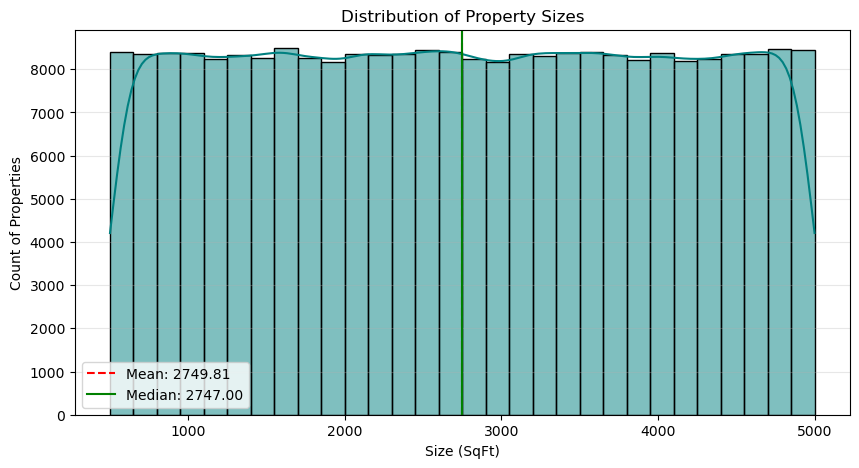

In [7]:
size_stats = df['Size_in_SqFt'].describe()
print(f"--- Property Size Distribution Statistics  ---")
print(size_stats)
print(f"Skewness: {df['Size_in_SqFt'].skew():.2f}")

# 2. Plot the Distribution
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x=df['Size_in_SqFt'], kde=True, bins=30, color='teal')

# Add lines for mean and median
plt.axvline(df['Size_in_SqFt'].mean(), color='red', linestyle='--', label=f"Mean: {df['Size_in_SqFt'].mean():.2f}")
plt.axvline(df['Size_in_SqFt'].median(), color='green', linestyle='-', label=f"Median: {df['Size_in_SqFt'].median():.2f}")

plt.title('Distribution of Property Sizes')
plt.xlabel('Size (SqFt)')
plt.ylabel('Count of Properties')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

In [12]:
df1 = pd.read_csv("india_housing_prices.csv")

--- Price per SqFt Summary by Property Type ---
                   count  mean  median   std
Property_Type                               
Apartment          82956  0.13    0.09  0.13
Independent House  83300  0.13    0.09  0.13
Villa              83744  0.13    0.09  0.13


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\3607104993.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df1, x='Property_Type', y='Price_per_SqFt', palette='Set2')


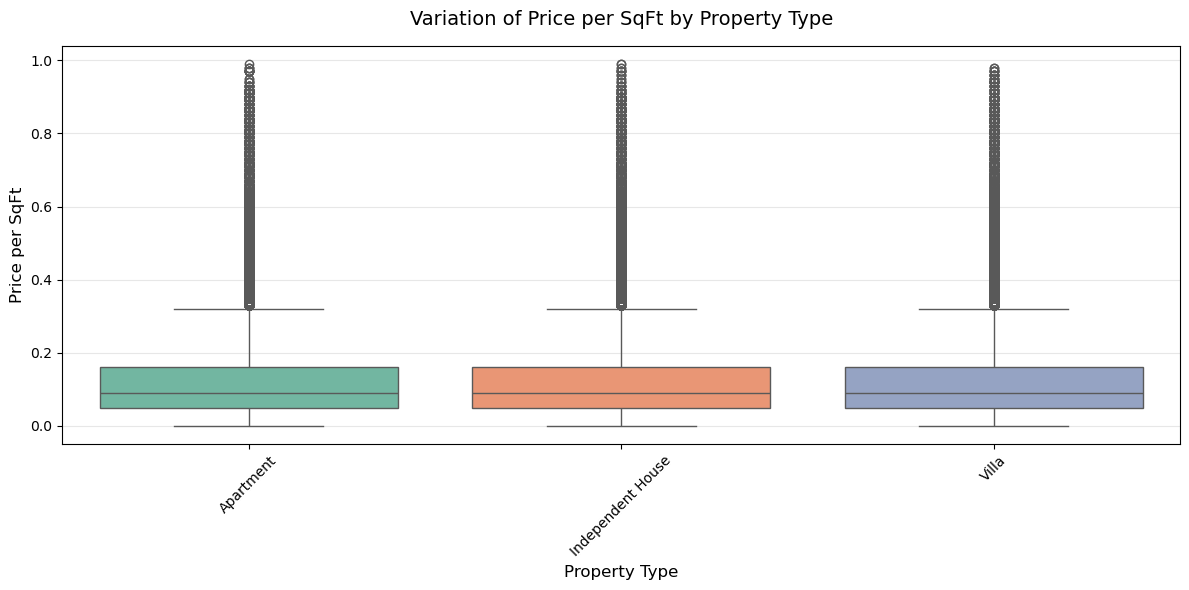

In [14]:
#How does the price per sq ft vary by property type?

from sklearn.preprocessing import LabelEncoder



# 1. Calculate Summary Statistics Grouped by Property Type
ppsf_summary = df1.groupby('Property_Type')['Price_per_SqFt'].agg(['count', 'mean', 'median', 'std']).round(2)
print("--- Price per SqFt Summary by Property Type ---")
print(ppsf_summary.sort_values(by='median', ascending=False))

# 2. Visualize using a Box Plot (to see distributions and spreads)
plt.figure(figsize=(12, 6))
sns.boxplot(data=df1, x='Property_Type', y='Price_per_SqFt', palette='Set2')


plt.title('Variation of Price per SqFt by Property Type', fontsize=14, pad=15)
plt.xlabel('Property Type', fontsize=12)
plt.ylabel('Price per SqFt', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:
df.columns

Index(['Unnamed: 0', 'ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK',
       'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built',
       'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property',
       'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility',
       'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type',
       'Availability_Status', 'Good_Investment', 'Future_Price_5Y'],
      dtype='object')

--- Size vs Price Relationship Strength ---
Pearson Correlation (Linear relationship): -0.00
Spearman Correlation (Trend relationship):  -0.00


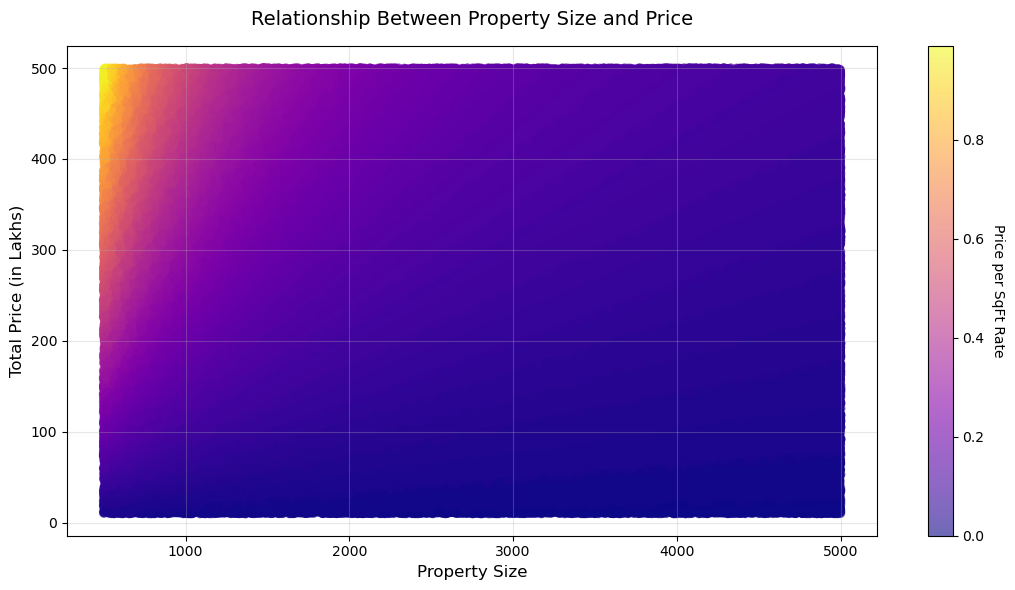

In [18]:
# Is there a relationship between property size and price?


# 1. Map columns (verify the names match your dataframe exactly)
size_col = 'Size_in_SqFt'
price_col = 'Price_in_Lakhs'
ppsf_col = 'Price_per_SqFt'

# 2. Print statistical correlation scores
print(f"--- Size vs Price Relationship Strength ---")
print(f"Pearson Correlation (Linear relationship): {df[size_col].corr(df[price_col], method='pearson'):.2f}")
print(f"Spearman Correlation (Trend relationship):  {df[size_col].corr(df[price_col], method='spearman'):.2f}")

# 3. Create the visual scatter plot
plt.figure(figsize=(11, 6))
scatter = plt.scatter(
    data=df,
    x=size_col,
    y=price_col,
    c=df[ppsf_col],     # Colors the dots by their price per sqft rate
    cmap='plasma',      # High-contrast color gradient
    alpha=0.6
)

# Add a legend bar for the color gradient
cbar = plt.colorbar(scatter)
cbar.set_label('Price per SqFt Rate', rotation=270, labelpad=15)

plt.title('Relationship Between Property Size and Price', fontsize=14, pad=15)
plt.xlabel('Property Size', fontsize=12)
plt.ylabel('Total Price (in Lakhs)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [19]:
size_col = 'Size_in_SqFt'
ppsf_col = 'Price_per_SqFt'

def find_outliers_iqr(dataframe, column):
    Q1 = dataframe[column].quantile(0.25)
    Q3 = dataframe[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = dataframe[(dataframe[column] < lower_bound) | (dataframe[column] > upper_bound)]
    return outliers, lower_bound, upper_bound

# 1. Identify Outliers for Size
size_outliers, size_low, size_high = find_outliers_iqr(df, size_col)
print(f"--- Outlier Detection for {size_col} ---")
print(f"Valid Range: {size_low:.2f} to {size_high:.2f}")
print(f"Number of Outliers: {len(size_outliers)} ({len(size_outliers)/len(df):.2%})\n")

# 2. Identify Outliers for Price per SqFt
ppsf_outliers, ppsf_low, ppsf_high = find_outliers_iqr(df, ppsf_col)
print(f"--- Outlier Detection for {ppsf_col} ---")
print(f"Valid Range: {ppsf_low:.2f} to {ppsf_high:.2f}")
print(f"Number of Outliers: {len(ppsf_outliers)} ({len(ppsf_outliers)/len(df):.2%})")


--- Outlier Detection for Size_in_SqFt ---
Valid Range: -1753.50 to 7250.50
Number of Outliers: 0 (0.00%)

--- Outlier Detection for Price_per_SqFt ---
Valid Range: -0.12 to 0.33
Number of Outliers: 20020 (8.01%)


In [20]:
# Use the upper bound discovered by your IQR function to drop outliers
ppsf_upper_bound = 0.33

# Filter the dataset
df_clean = df[df['Price_per_SqFt'] <= ppsf_upper_bound]

print(f"Original dataset rows: {len(df)}")
print(f"Cleaned dataset rows:  {len(df_clean)}")


Original dataset rows: 250000
Cleaned dataset rows:  231130


--- Cleaned Size vs Price Relationship Strength ---
New Pearson Correlation: 0.13
New Spearman Correlation:  0.12


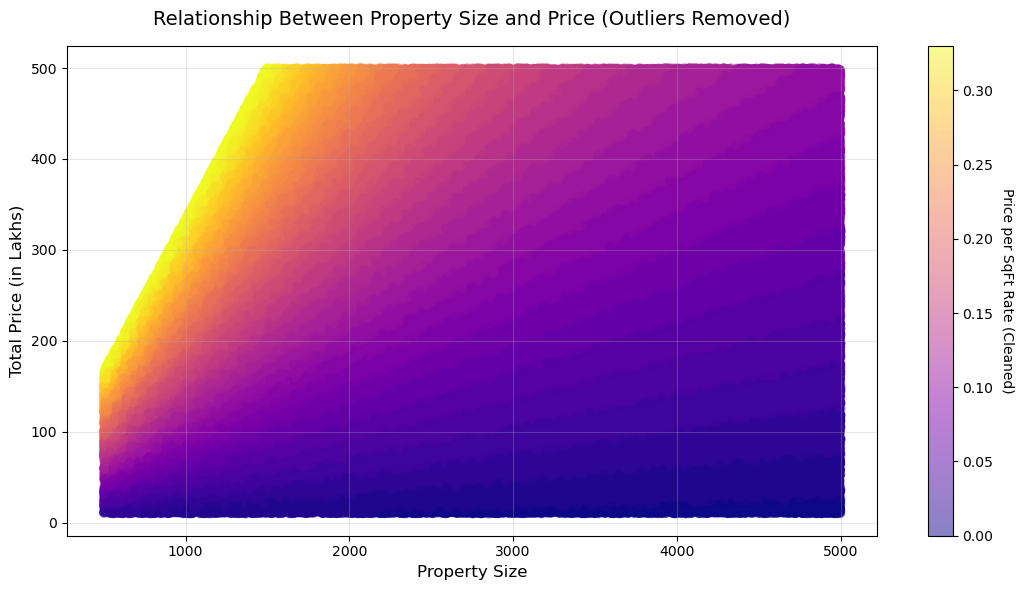

In [21]:
size_col = 'Size_in_SqFt'
price_col = 'Price_in_Lakhs'
ppsf_col = 'Price_per_SqFt'

# 1. Print new statistical correlation scores
print(f"--- Cleaned Size vs Price Relationship Strength ---")
print(f"New Pearson Correlation: {df_clean[size_col].corr(df_clean[price_col], method='pearson'):.2f}")
print(f"New Spearman Correlation:  {df_clean[size_col].corr(df_clean[price_col], method='spearman'):.2f}")

# 2. Create the clean visual scatter plot
plt.figure(figsize=(11, 6))
scatter = plt.scatter(
    data=df_clean,
    x=size_col,
    y=price_col,
    c=df_clean[ppsf_col],
    cmap='plasma',
    alpha=0.5
)

cbar = plt.colorbar(scatter)
cbar.set_label('Price per SqFt Rate (Cleaned)', rotation=270, labelpad=15)

plt.title('Relationship Between Property Size and Price (Outliers Removed)', fontsize=14, pad=15)
plt.xlabel('Property Size', fontsize=12)
plt.ylabel('Total Price (in Lakhs)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


6–10: Location-based Analysis


--- Average Price per SqFt by State ---
         State  Price_per_SqFt
 Uttar Pradesh        0.101534
   Maharashtra        0.101182
     Karnataka        0.100811
Andhra Pradesh        0.100580
     Telangana        0.100553
Madhya Pradesh        0.100214
     Jharkhand        0.100180
       Gujarat        0.099869
       Haryana        0.099746
        Punjab        0.099738
    Tamil Nadu        0.099685
         Bihar        0.099556
         Assam        0.099549
        Odisha        0.099527
        Kerala        0.099475
     Rajasthan        0.099394
   Uttarakhand        0.099322
   West Bengal        0.099275
  Chhattisgarh        0.099211
         Delhi        0.098951


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\1223729243.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


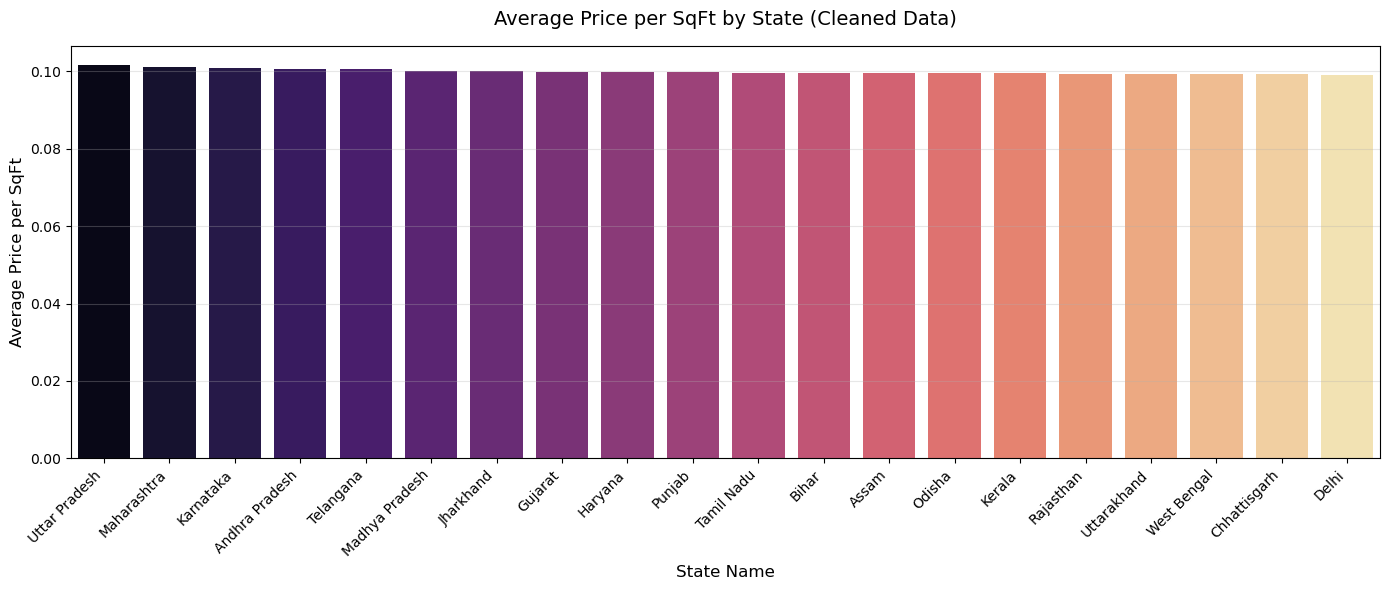

In [23]:
#What is the average price per sq ft by state?
# --- Step 1: Filter Out Extreme Outliers dynamically ---
# Real estate datasets often contain massive outlier prices that distort averages.
Q1 = df['Price_per_SqFt'].quantile(0.25)
Q3 = df['Price_per_SqFt'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

# Keep only rows within the valid distribution limit
df_clean = df1[df1['Price_per_SqFt'] <= upper_bound]


# --- Step 2: Calculate Average Price per Sq Ft by State ---
# Group by the text column and find the mean
state_ppsf = df_clean.groupby('State')['Price_per_SqFt'].mean().reset_index()

# Sort the values from highest average price to lowest
state_ppsf = state_ppsf.sort_values(by='Price_per_SqFt', ascending=False)

print("--- Average Price per SqFt by State ---")
print(state_ppsf.to_string(index=False))


# --- Step 3: Visualize with Actual State Names ---
plt.figure(figsize=(14, 6))
sns.barplot(
    data=state_ppsf, 
    x='State', 
    y='Price_per_SqFt', 
    palette='magma',
    order=state_ppsf['State']  # Enforces our high-to-low sorted ranking
)

plt.title('Average Price per SqFt by State (Cleaned Data)', fontsize=14, pad=15)
plt.xlabel('State Name', fontsize=12)
plt.ylabel('Average Price per SqFt', fontsize=12)
plt.xticks(rotation=45, ha='right')  # Tilts the text names so they do not overlap
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



--- Top 15 Most Expensive Cities (Average Price in Lakhs) ---
          City  Price_in_Lakhs
     Bangalore      258.456639
         Surat      258.080467
         Kochi      257.415221
          Gaya      257.053391
     Mangalore      256.920925
      Dehradun      256.890115
        Mysore      256.848172
       Chennai      256.830172
     Hyderabad      256.594051
    Coimbatore      256.504745
        Bhopal      256.498896
          Pune      256.495661
         Noida      256.287206
       Lucknow      256.212431
Vishakhapatnam      255.772442


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\4255487869.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


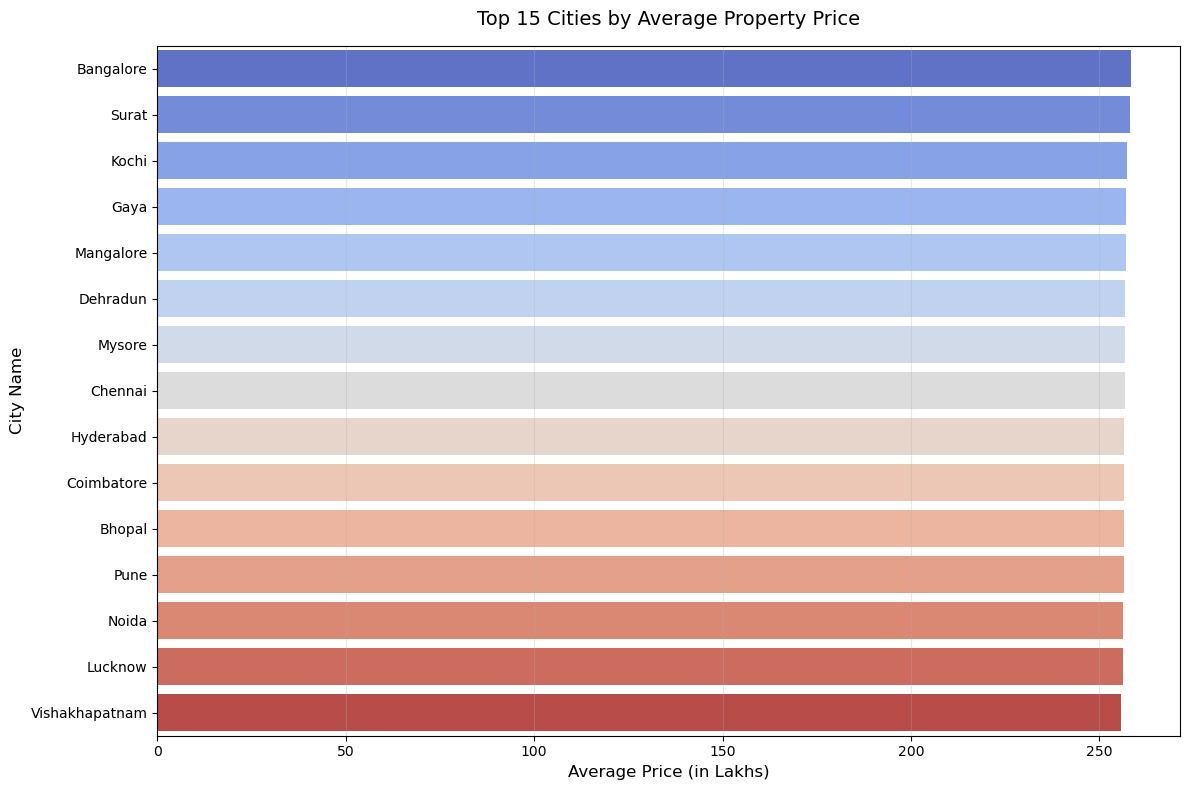

In [25]:
#What is the average property price by city?


city_prices = df1.groupby('City')['Price_in_Lakhs'].mean().reset_index()


city_prices = city_prices.sort_values(by='Price_in_Lakhs', ascending=False)

print("--- Top 15 Most Expensive Cities (Average Price in Lakhs) ---")
print(city_prices.head(15).to_string(index=False))

# 2. Visualize the Top 15 cities using a horizontal bar plot
# A horizontal plot makes long city names much easier to read without overlapping
plt.figure(figsize=(12, 8))
top_15_cities = city_prices.head(15)

sns.barplot(
    data=top_15_cities,
    x='Price_in_Lakhs',
    y='City',
    palette='coolwarm',
    order=top_15_cities['City']  # Enforces high-to-low ranking
)

plt.title('Top 15 Cities by Average Property Price', fontsize=14, pad=15)
plt.xlabel('Average Price (in Lakhs)', fontsize=12)
plt.ylabel('City Name', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

--- Top 10 Localities with the Oldest Properties (Median Age_of_Property) ---
    Locality  Age_of_Property
 Locality_72             21.0
Locality_403             21.0
  Locality_1             20.0
Locality_299             20.0
Locality_344             20.0
Locality_334             20.0
Locality_320             20.0
Locality_302             20.0
Locality_300             20.0
 Locality_30             20.0

--- Top 10 Localities with the Newest/Most Modern Properties ---
    Locality  Age_of_Property
Locality_171             17.0
Locality_186             17.0
Locality_409             17.0
Locality_181             17.0
Locality_179             17.0
Locality_119             17.0
Locality_118             17.0
 Locality_78             17.0
Locality_421             17.0
Locality_443             16.0


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\514959470.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


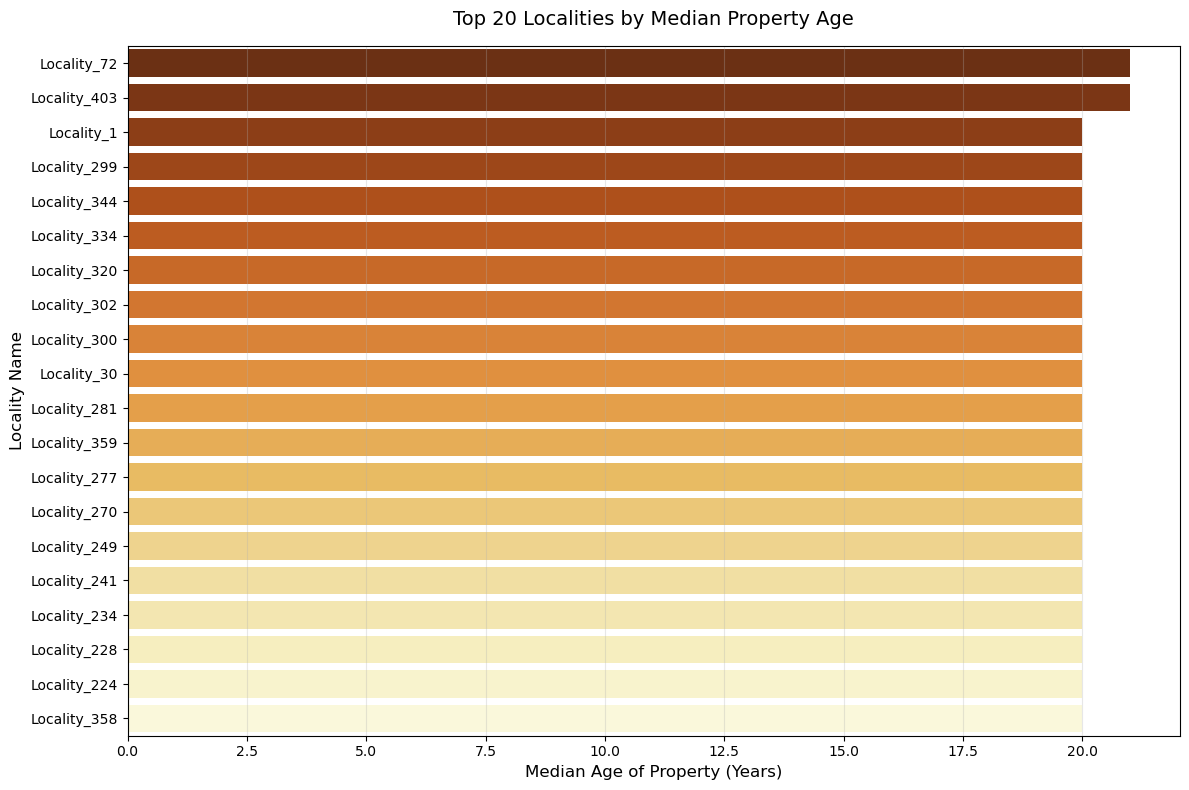

In [30]:
locality_age = df1.groupby('Locality')['Age_of_Property'].median().reset_index()

# Sort from the oldest neighborhoods to the newest
locality_age = locality_age.sort_values(by='Age_of_Property', ascending=False)

print(f"--- Top 10 Localities with the Oldest Properties (Median {'Age_of_Property'}) ---")
print(locality_age.head(10).to_string(index=False))

print(f"\n--- Top 10 Localities with the Newest/Most Modern Properties ---")
print(locality_age.tail(10).to_string(index=False))

# 3. Visualize the Top 20 Localities with the oldest median property age
plt.figure(figsize=(12, 8))
top_20_localities = locality_age.head(20)

sns.barplot(
    data=top_20_localities,
    x='Age_of_Property',
    y='Locality',
    palette='YlOrBr_r',  # FIX: Switched to a valid built-in sequential palette name
    order=top_20_localities['Locality']
)

plt.title(f'Top 20 Localities by Median Property Age', fontsize=14, pad=15)
plt.xlabel('Median Age of Property (Years)', fontsize=12)
plt.ylabel('Locality Name', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


--- BHK Distribution Matrix across Top 10 Cities (Counts) ---
BHK             1     2     3     4     5
City                                     
Ahmedabad    1264  1267  1272  1258  1350
Bhubaneswar  1236  1293  1299  1217  1278
Coimbatore   1236  1301  1317  1345  1262
Cuttack      1320  1292  1301  1236  1209
Durgapur     1311  1259  1287  1260  1270
Jamshedpur   1274  1221  1324  1273  1243
Kochi        1270  1268  1207  1280  1280
New Delhi    1297  1184  1300  1281  1244
Silchar      1241  1255  1324  1248  1336
Vijayawada   1204  1288  1292  1335  1225

--- BHK Distribution Mix within Each City (Percentages) ---
BHK             1     2     3     4     5
City                                     
Ahmedabad    19.7  19.8  19.8  19.6  21.1
Bhubaneswar  19.5  20.4  20.5  19.2  20.2
Coimbatore   19.1  20.1  20.4  20.8  19.5
Cuttack      20.8  20.3  20.5  19.4  19.0
Durgapur     20.5  19.7  20.2  19.7  19.9
Jamshedpur   20.1  19.3  20.9  20.1  19.6
Kochi        20.1  20.1  19.1  20.3  

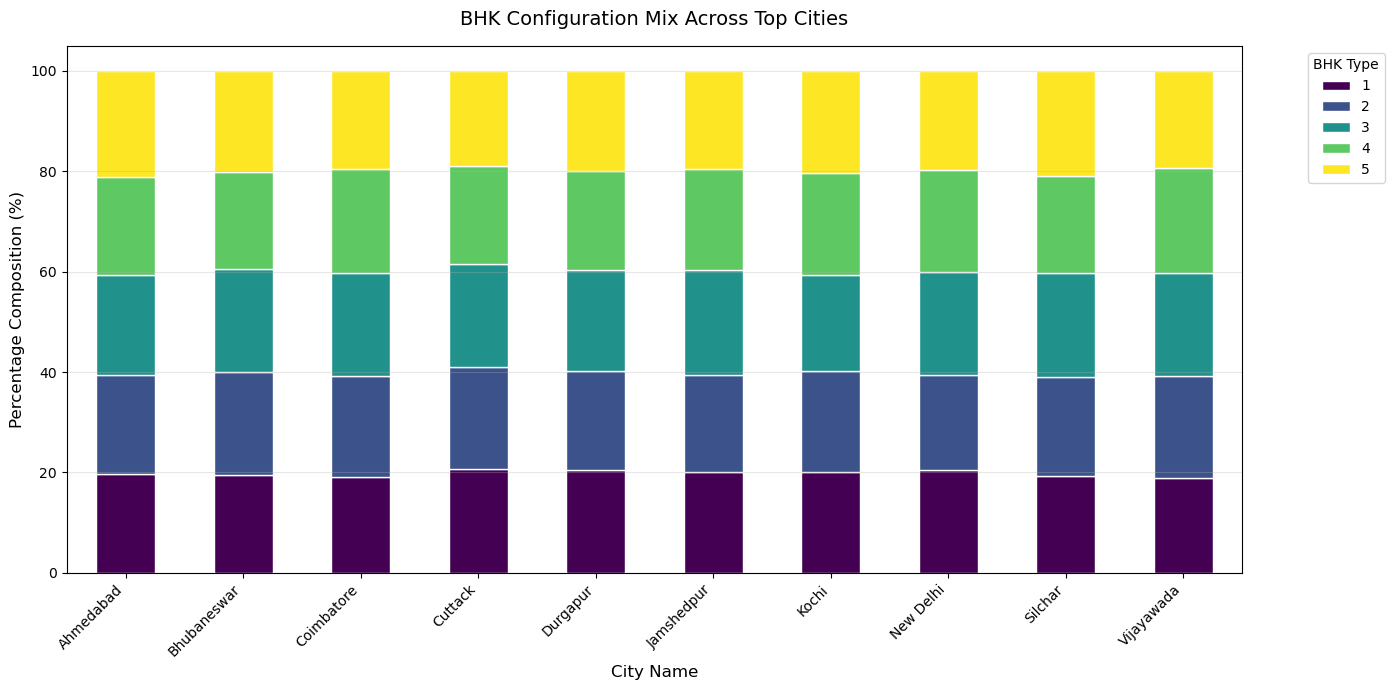

In [32]:


# 2. Create a Cross-Tabulation Matrix (Cities vs BHK configuration counts)
# We take the top 10 most frequent cities to keep the visualization clear and readable
top_cities = df1['City'].value_counts().head(10).index
df_top_cities = df1[df1['City'].isin(top_cities)]

bhk_cross_tab = pd.crosstab(df_top_cities['City'], df_top_cities['BHK'])
print("--- BHK Distribution Matrix across Top 10 Cities (Counts) ---")
print(bhk_cross_tab)

# 3. Create a Percentage-based Cross-Tabulation for a normalized comparison
bhk_pct_cross_tab = pd.crosstab(df_top_cities['City'], df_top_cities['BHK'], normalize='index') * 100
print("\n--- BHK Distribution Mix within Each City (Percentages) ---")
print(bhk_pct_cross_tab.round(1))

# 4. Plot a Stacked Bar Chart showing the market mix
plt.figure(figsize=(14, 7))
bhk_pct_cross_tab.plot(kind='bar', stacked=True, cmap='viridis', edgecolor='white', ax=plt.gca())

plt.title('BHK Configuration Mix Across Top Cities', fontsize=14, pad=15)
plt.xlabel('City Name', fontsize=12)
plt.ylabel('Percentage Composition (%)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='BHK Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


--- Top 5 Most Expensive Localities Isolated ---
1. 328
2. 296
3. 441
4. 290
5. 116


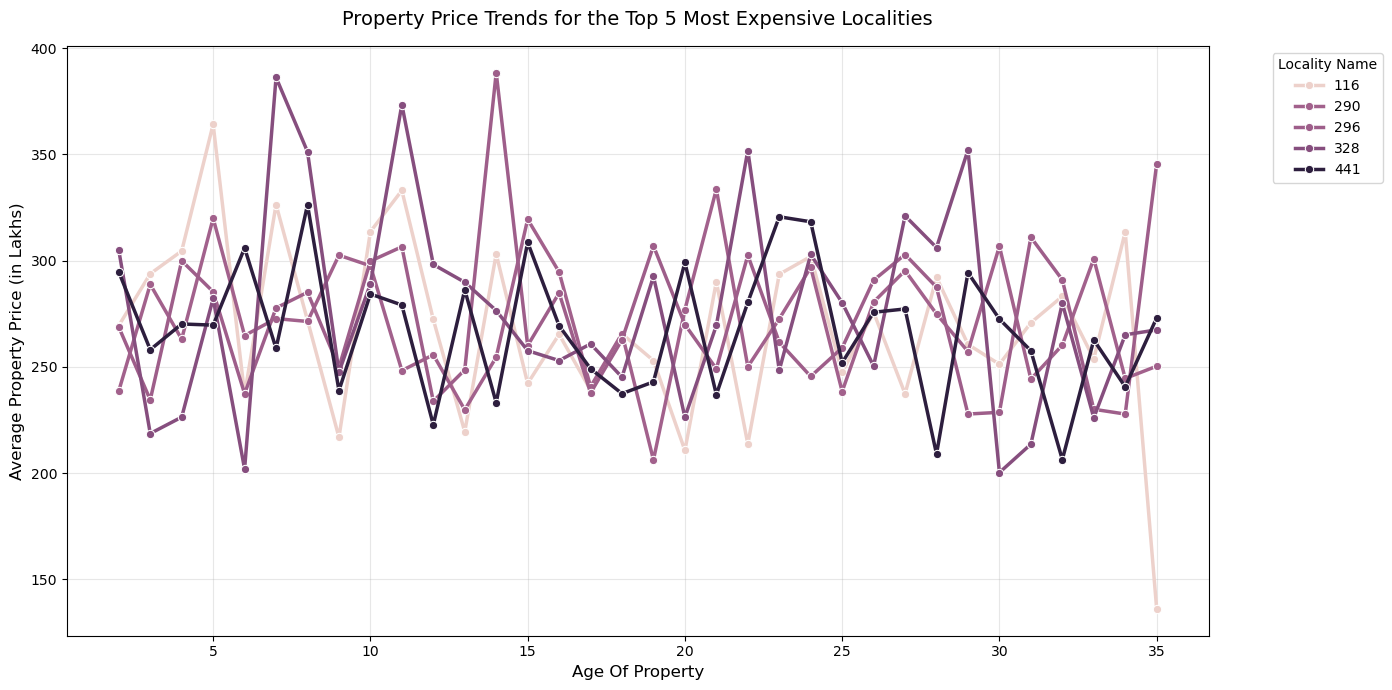

In [34]:

# 1. Identify valid columns in your dataset
price_col = 'Price_in_Lakhs'
loc_col = 'Locality'

time_col = 'Age_of_Property'

# 2. Find the top 5 most expensive localities by historical average price
top_5_expensive_localities = (
    df.groupby(loc_col)[price_col]
    .mean()
    .sort_values(ascending=False)
    .head(5)
    .index.tolist()
)

print("--- Top 5 Most Expensive Localities Isolated ---")
for i, name in enumerate(top_5_expensive_localities, 1):
    print(f"{i}. {name}")

# 3. Filter data down strictly to these premium zones
df_trends = df[df[loc_col].isin(top_5_expensive_localities)]

# 4. Group by Locality and Time to get smooth sequential averages
trend_data = (
    df_trends.groupby([time_col, loc_col])[price_col]
    .mean()
    .reset_index()
)

# 5. Visualize the lines
plt.figure(figsize=(14, 7))
sns.lineplot(
    data=trend_data, 
    x=time_col, 
    y=price_col, 
    hue=loc_col, 
    marker='o', 
    linewidth=2.5
)

plt.title('Property Price Trends for the Top 5 Most Expensive Localities', fontsize=14, pad=15)
plt.xlabel(f'{time_col.replace("_", " ").title()}', fontsize=12)
plt.ylabel('Average Property Price (in Lakhs)', fontsize=12)
plt.legend(title='Locality Name', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


11–15: Feature Relationship & Correlation

Numerical features being cross-analyzed:
['ID', 'BHK', 'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built', 'Floor_No', 'Total_Floors', 'Age_of_Property', 'Nearby_Schools', 'Nearby_Hospitals']


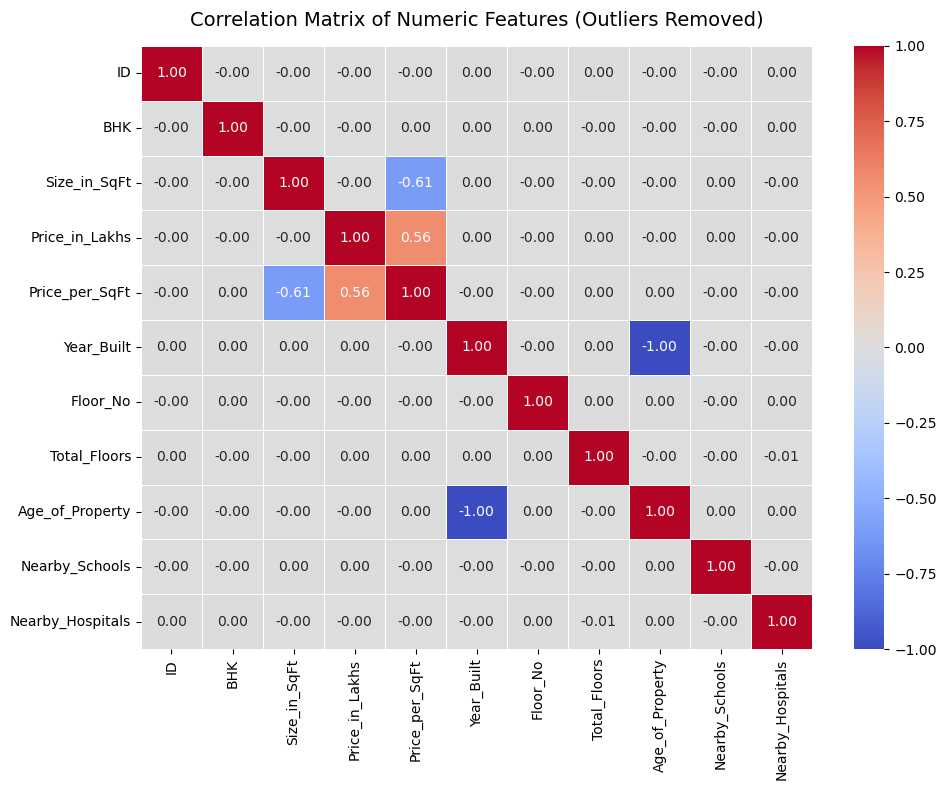

In [35]:
#How are numeric features correlated with each other?

num_cols = df1.select_dtypes(include=['int64', 'float64']).columns.tolist()

print("Numerical features being cross-analyzed:")
print(num_cols)

# 2. Compute the Pearson correlation matrix
corr_matrix = df1[num_cols].corr(method='pearson')

# 3. Render the correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, 
    annot=True,          # Writes the exact correlation numbers on top of the colors
    cmap='coolwarm',     # Red for positive correlation, Blue for negative correlation
    fmt=".2f",           # Limits decimal places to two
    linewidths=0.5,      # Adds clear white border lines between the blocks
    vmin=-1, vmax=1      # Standardizes the scale boundaries between -1 and +1
)

plt.title('Correlation Matrix of Numeric Features (Outliers Removed)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()


--- Price per SqFt Summary by Number of Nearby Schools ---
                count   mean  median
Nearby_Schools                      
1               25360  0.131    0.09
2               24851  0.131    0.09
3               25045  0.131    0.09
4               24739  0.129    0.09
5               25023  0.130    0.09
6               24824  0.133    0.09
7               24808  0.130    0.09
8               25290  0.130    0.09
9               24823  0.131    0.09
10              25237  0.131    0.09


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\3819616903.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


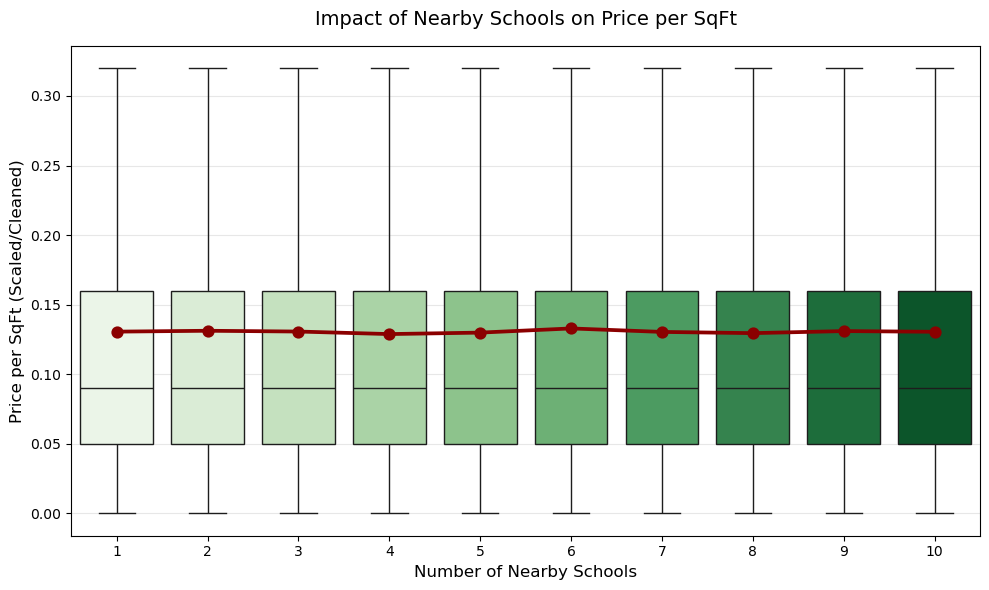

In [37]:
#How do nearby schools relate to price per sq ft?

# 1. Identify the column names
schools_col = 'Nearby_Schools'
ppsf_col = 'Price_per_SqFt'

# Calculate the mean and median price per sq ft for each school count tier
school_summary = df1.groupby(schools_col)[ppsf_col].agg(['count', 'mean', 'median']).round(3)
print("--- Price per SqFt Summary by Number of Nearby Schools ---")
print(school_summary)

# 2. Visualize using a Box Plot with an overlaid mean trend line
plt.figure(figsize=(10, 6))

# Main box plot to see distribution spreads
sns.boxplot(
    data=df1, 
    x=schools_col, 
    y=ppsf_col, 
    palette='Greens',
    showfliers=False # Hides remaining mild outliers so you can see the boxes clearly
)

# Overlaid point plot to show the explicit trend of the average (mean) values
sns.pointplot(
    data=df1, 
    x=schools_col, 
    y=ppsf_col, 
    color='darkred', 
    estimator='mean', 
    errorbar=None, 
    markers='o', 
    linestyles='-'
)

plt.title('Impact of Nearby Schools on Price per SqFt', fontsize=14, pad=15)
plt.xlabel('Number of Nearby Schools', fontsize=12)
plt.ylabel('Price per SqFt (Scaled/Cleaned)', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



--- Price per SqFt Summary by Number of Nearby_Hospitals ---
                  count   mean  median
Nearby_Hospitals                      
1                 23071  0.100    0.09
2                 23017  0.100    0.09
3                 22778  0.101    0.09
4                 23230  0.100    0.09
5                 23174  0.100    0.08
6                 23034  0.099    0.08
7                 22804  0.101    0.09
8                 22849  0.100    0.08
9                 23020  0.101    0.09
10                23003  0.099    0.09


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\1040321177.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


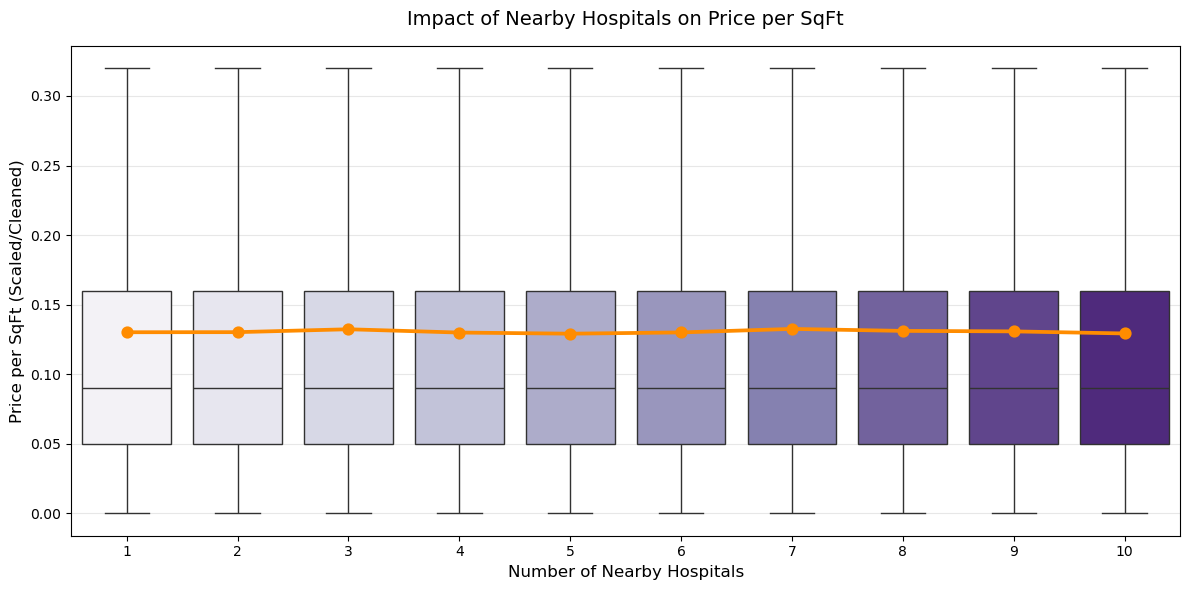

In [43]:
#How do nearby hospitals relate to price per sq ft?



# 1. Automatically find the correct column name for hospitals
hospitals_col = 'Nearby_Hospitals'


ppsf_col = 'Price_per_SqFt'

# Calculate the mean and median summary metrics
hospital_summary = df_clean.groupby('Nearby_Hospitals')[ppsf_col].agg(['count', 'mean', 'median']).round(3)
print(f"--- Price per SqFt Summary by Number of {'Nearby_Hospitals'} ---")
print(hospital_summary)

# 2. Visualize using a Box Plot with an overlaid mean trend line
plt.figure(figsize=(12, 6))

# Main box plot
sns.boxplot(
    data=df, 
    x='Nearby_Hospitals', 
    y=ppsf_col, 
    palette='Purples',  # Purple theme for medical/hospital infrastructure
    showfliers=False    # Hides extreme fliers to keep the boxes in clear view
)

# Overlaid trend line tracking the average (mean) values
sns.pointplot(
    data=df, 
    x='Nearby_Hospitals', 
    y=ppsf_col, 
    color='darkorange', 
    estimator='mean', 
    errorbar=None, 
    markers='o', 
    linestyles='-'
)

plt.title('Impact of Nearby Hospitals on Price per SqFt', fontsize=14, pad=15)
plt.xlabel('Number of Nearby Hospitals', fontsize=12)
plt.ylabel('Price per SqFt (Scaled/Cleaned)', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



In [41]:
df1.columns


Index(['ID', 'State', 'City', 'Locality', 'Property_Type', 'BHK',
       'Size_in_SqFt', 'Price_in_Lakhs', 'Price_per_SqFt', 'Year_Built',
       'Furnished_Status', 'Floor_No', 'Total_Floors', 'Age_of_Property',
       'Nearby_Schools', 'Nearby_Hospitals', 'Public_Transport_Accessibility',
       'Parking_Space', 'Security', 'Amenities', 'Facing', 'Owner_Type',
       'Availability_Status'],
      dtype='object')

--- Total Price (Lakhs) Summary by Furnished Status ---
                  count    mean  median     std
Furnished_Status                               
Unfurnished       76793  243.65  236.60  139.82
Furnished         76548  242.93  235.44  139.51
Semi-furnished    76639  242.55  235.20  139.64


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\1087105141.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\1087105141.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


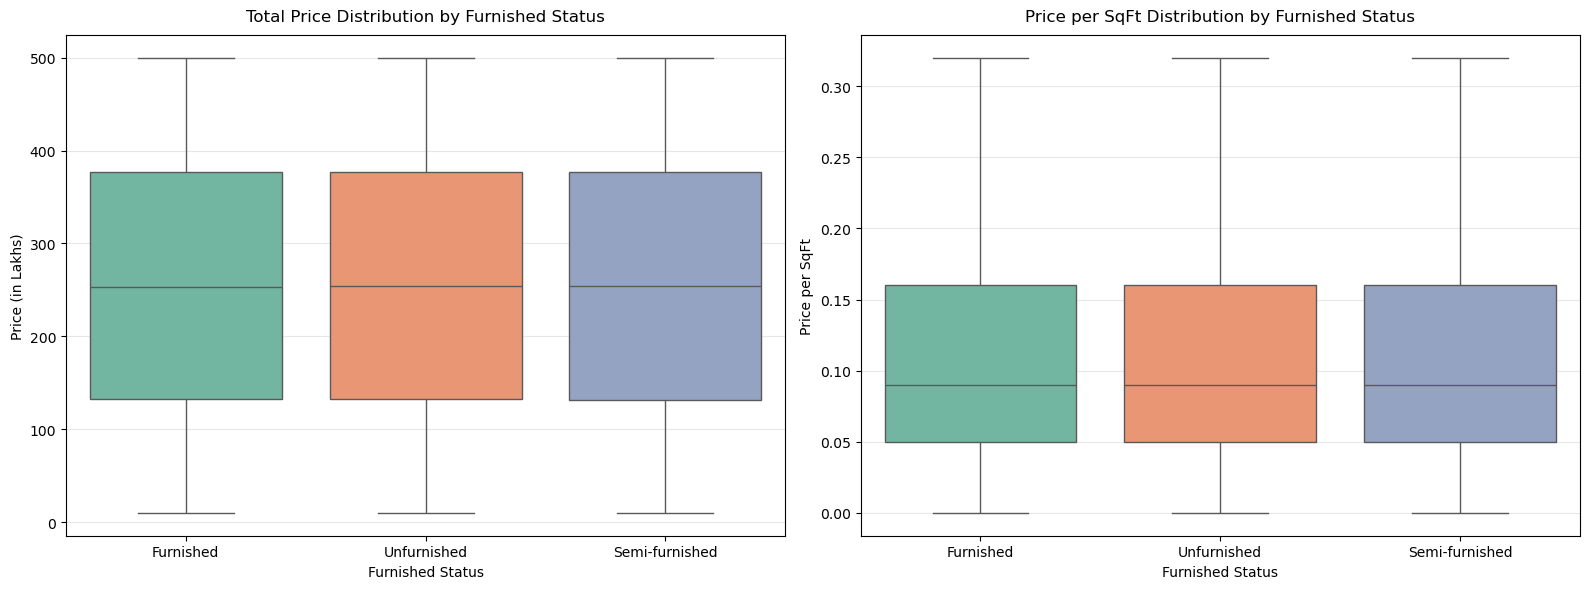

In [44]:
#How does price vary by furnished status?
# 1. Calculate Descriptive Summary Statistics grouped by Furnished Status
furnished_summary = df_clean.groupby('Furnished_Status')['Price_in_Lakhs'].agg(['count', 'mean', 'median', 'std']).round(2)
print("--- Total Price (Lakhs) Summary by Furnished Status ---")
print(furnished_summary.sort_values(by='median', ascending=False))

# 2. Set up a side-by-side subplot visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Distribution of Total Price by Furnished Status
sns.boxplot(
    data=df1, 
    x='Furnished_Status', 
    y='Price_in_Lakhs', 
    palette='Set2', 
    ax=axes[0],
    showfliers=False  # Hides extreme fliers to focus on box body midpoints
)
axes[0].set_title('Total Price Distribution by Furnished Status', fontsize=12, pad=10)
axes[0].set_xlabel('Furnished Status', fontsize=10)
axes[0].set_ylabel('Price (in Lakhs)', fontsize=10)
axes[0].grid(axis='y', alpha=0.3)

# Right Plot: Distribution of Price per SqFt by Furnished Status
sns.boxplot(
    data=df1, 
    x='Furnished_Status', 
    y='Price_per_SqFt', 
    palette='Set2', 
    ax=axes[1],
    showfliers=False
)
axes[1].set_title('Price per SqFt Distribution by Furnished Status', fontsize=12, pad=10)
axes[1].set_xlabel('Furnished Status', fontsize=10)
axes[1].set_ylabel('Price per SqFt', fontsize=10)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()



--- Price per SqFt Summary by Property Facing Direction ---
        count  mean  median    std
Facing                            
East    57307   0.1    0.09  0.072
North   57640   0.1    0.09  0.072
South   57377   0.1    0.09  0.072
West    57656   0.1    0.09  0.072


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\2654601755.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


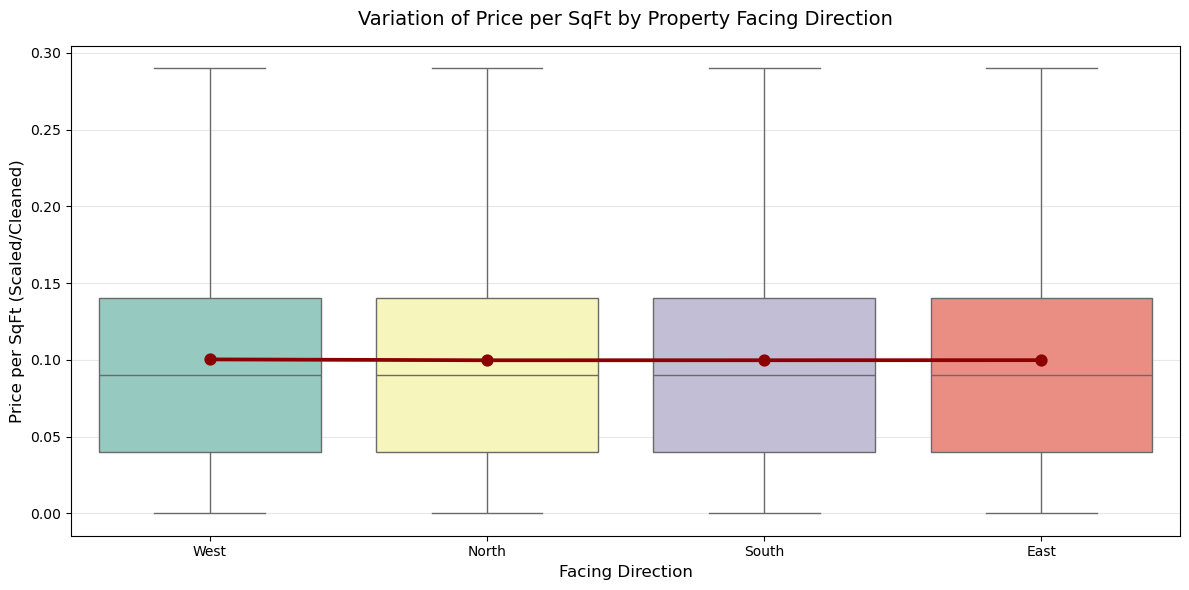

In [45]:
#How does price per sq ft vary by property facing direction?
# 1. Automatically find the correct column name for property facing direction
ppsf_col = 'Price_per_SqFt'

# Calculate the mean and median price per sq ft for each direction group
facing_summary = df_clean.groupby('Facing')[ppsf_col].agg(['count', 'mean', 'median', 'std']).round(3)
print(f"--- Price per SqFt Summary by Property {'Facing'} Direction ---")
print(facing_summary.sort_values(by='median', ascending=False))

# 2. Visualize using a Box Plot with an overlaid mean trend line
plt.figure(figsize=(12, 6))

# Main box plot
sns.boxplot(
    data=df_clean, 
    x='Facing', 
    y=ppsf_col, 
    palette='Set3',
    showfliers=False # Hides remaining outliers to focus clearly on the box distributions
)

# Overlaid point plot tracking the average (mean) values across directions
sns.pointplot(
    data=df_clean, 
    x='Facing', 
    y=ppsf_col, 
    color='darkred', 
    estimator='mean', 
    errorbar=None, 
    markers='o', 
    linestyles='-'
)

plt.title('Variation of Price per SqFt by Property Facing Direction', fontsize=14, pad=15)
plt.xlabel('Facing Direction', fontsize=12)
plt.ylabel('Price per SqFt (Scaled/Cleaned)', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


16–20: Investment / Amenities / Ownership Analysis

--- Property Distribution by Owner Type ---
Owner_Type  Count  Percentage (%)
    Broker  83479           33.39
     Owner  83268           33.31
   Builder  83253           33.30


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\843969312.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


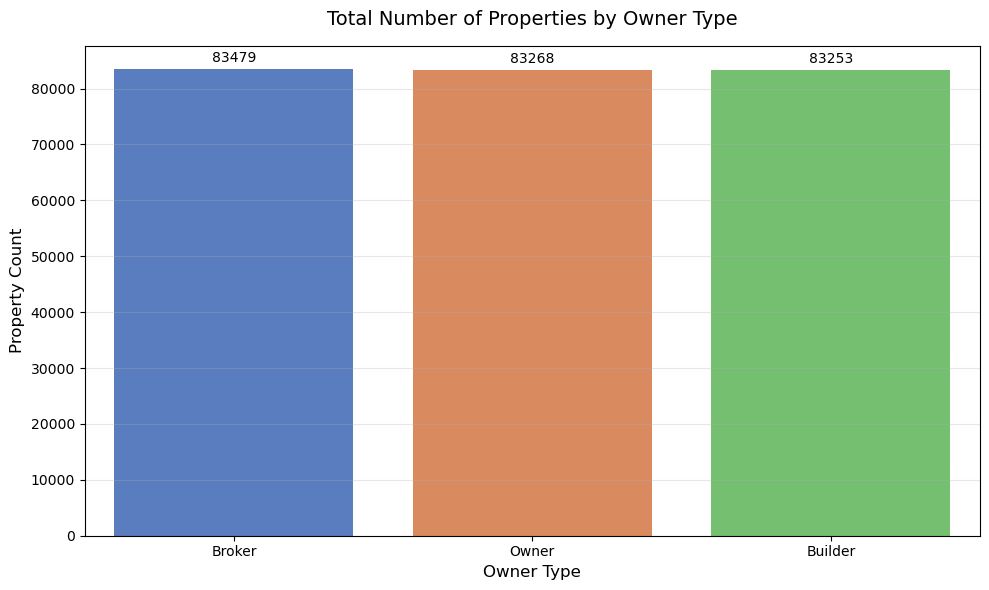

In [48]:
#How many properties belong to each owner type?
# 2. Calculate raw counts and percentage composition
owner_counts = df1['Owner_Type'].value_counts().reset_index()
owner_counts.columns = ['Owner_Type', 'Count']
owner_counts['Percentage (%)'] = (owner_counts['Count'] / len(df) * 100).round(2)

print("--- Property Distribution by Owner Type ---")
print(owner_counts.to_string(index=False))

# 3. Visualize using a clear bar plot
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=owner_counts,
    x='Owner_Type',
    y='Count',
    palette='muted',
    order=owner_counts['Owner_Type'] # Orders bars from highest count to lowest
)

# Overlay raw count values on top of each bar for immediate scanning
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge', padding=3)

plt.title('Total Number of Properties by Owner Type', fontsize=14, pad=15)
plt.xlabel('Owner Type', fontsize=12)
plt.ylabel('Property Count', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


--- Property Distribution by Availability Status ---
Availability_Status  Count  Percentage (%)
 Under_Construction 125035           50.01
      Ready_to_Move 124965           49.99


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\617575990.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


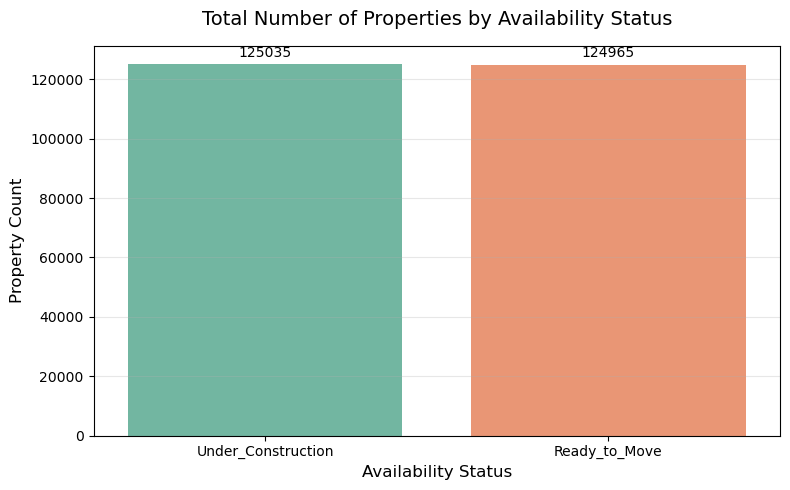

In [51]:
#How many properties are available under each availability status?
avail_counts = df1['Availability_Status'].value_counts().reset_index()
avail_counts.columns = ['Availability_Status', 'Count']
avail_counts['Percentage (%)'] = (avail_counts['Count'] / len(df) * 100).round(2)

print("--- Property Distribution by Availability Status ---")
print(avail_counts.to_string(index=False))

# 3. Visualize using a clear bar plot
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=avail_counts,
    x='Availability_Status',
    y='Count',
    palette='Set2',
    order=avail_counts['Availability_Status']  # Orders bars from highest count to lowest
)

# Overlay the exact counts on top of each bar for immediate scannability
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge', padding=3)

plt.title('Total Number of Properties by Availability Status', fontsize=14, pad=15)
plt.xlabel('Availability Status', fontsize=12)
plt.ylabel('Property Count', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


--- Price per SqFt Summary by Property Parking_Space Direction ---
                count  mean  median    std
Parking_Space                             
No             115345   0.1    0.09  0.072
Yes            114635   0.1    0.09  0.072


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\2340866792.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


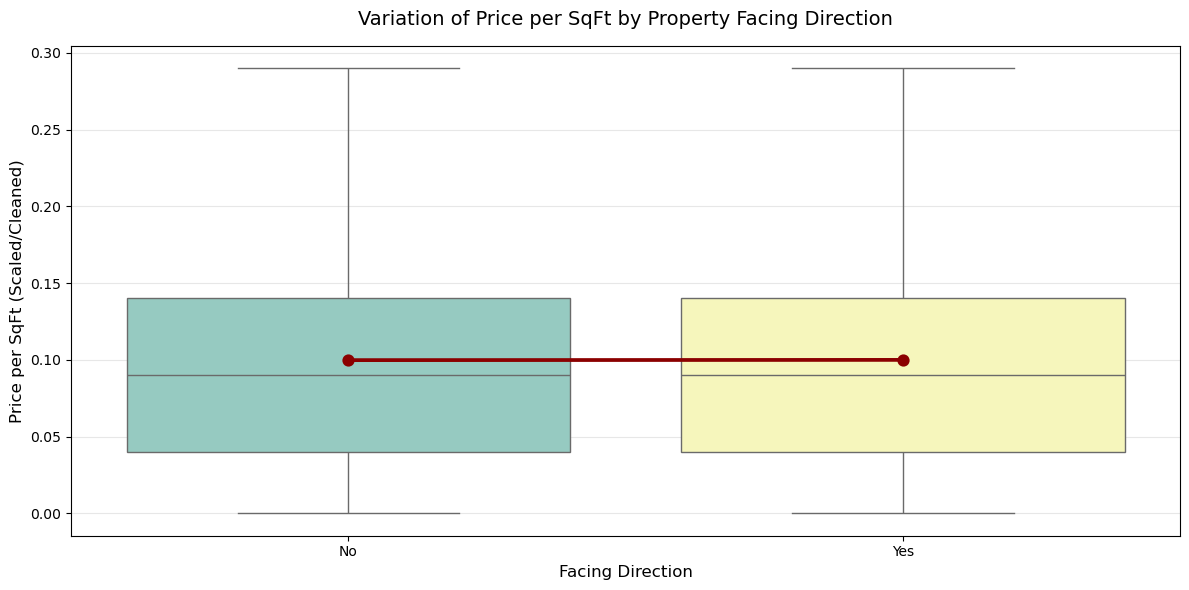

In [53]:
#Does parking space affect property price?

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Automatically find the correct column name for property facing direction


ppsf_col = 'Price_per_SqFt'

# Calculate the mean and median price per sq ft for each direction group
facing_summary = df_clean.groupby('Parking_Space')[ppsf_col].agg(['count', 'mean', 'median', 'std']).round(3)
print(f"--- Price per SqFt Summary by Property {'Parking_Space'} Direction ---")
print(facing_summary.sort_values(by='median', ascending=False))

# 2. Visualize using a Box Plot with an overlaid mean trend line
plt.figure(figsize=(12, 6))

# Main box plot
sns.boxplot(
    data=df_clean, 
    x='Parking_Space', 
    y=ppsf_col, 
    palette='Set3',
    showfliers=False # Hides remaining outliers to focus clearly on the box distributions
)

# Overlaid point plot tracking the average (mean) values across directions
sns.pointplot(
    data=df_clean, 
    x='Parking_Space', 
    y=ppsf_col, 
    color='darkred', 
    estimator='mean', 
    errorbar=None, 
    markers='o', 
    linestyles='-'
)

plt.title('Variation of Price per SqFt by Property Facing Direction', fontsize=14, pad=15)
plt.xlabel('Facing Direction', fontsize=12)
plt.ylabel('Price per SqFt (Scaled/Cleaned)', fontsize=12)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


--- Price per SqFt by Total Number of Amenities ---
               count  mean  median
Amenity_Count                     
1              46134   0.1    0.09
2              45834   0.1    0.09
3              45847   0.1    0.08
4              46273   0.1    0.09
5              45892   0.1    0.09

--- Price per SqFt by Individual Amenity Type ---
               count  mean  median
Amenity_List                      
Clubhouse     138016   0.1    0.09
Garden        138104   0.1    0.09
Gym           137931   0.1    0.09
Playground    137822   0.1    0.09
Pool          138022   0.1    0.09


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\2922534187.py:41: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_3844\2922534187.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


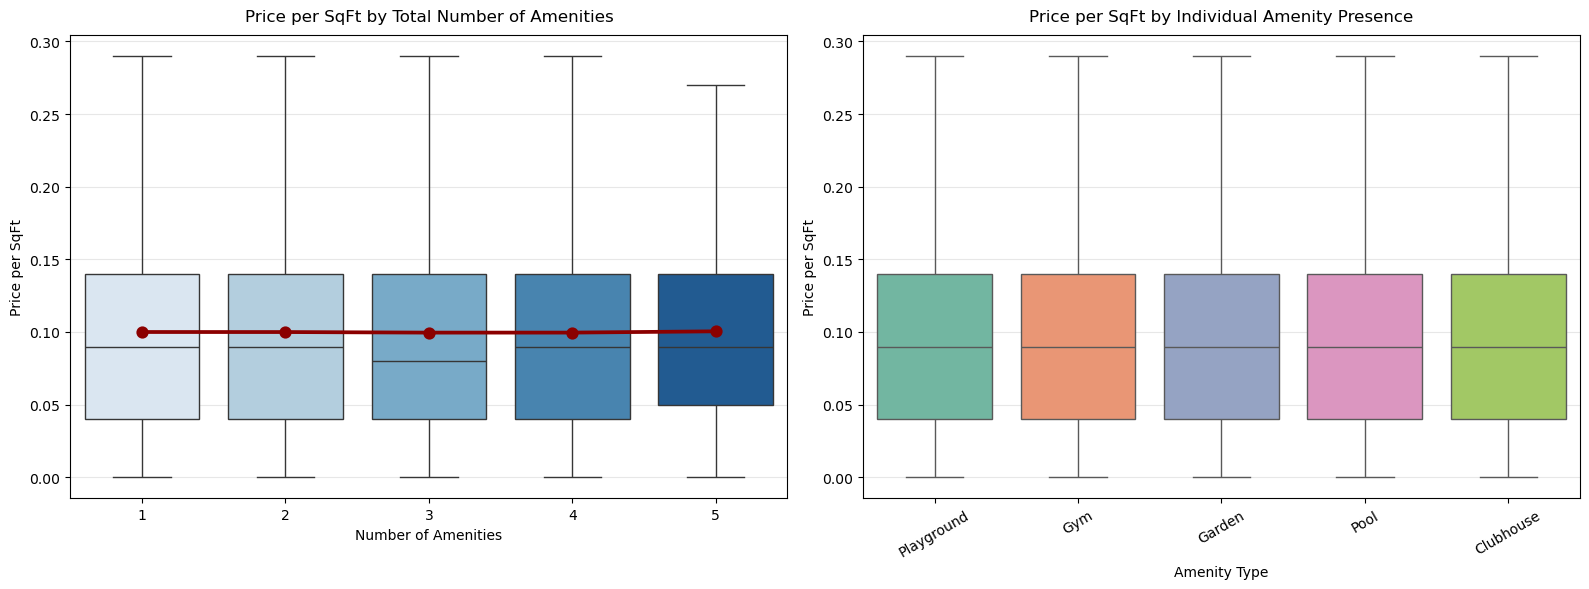

In [54]:
#How do amenities affect price per sq ft?


df_amen = df_clean.copy()

# --- PART 1: Analyze by Total Count of Amenities ---
# Clean quotes and split the comma-separated strings into Python lists
df_amen['Amenity_List'] = (
    df_amen['Amenities']
    .fillna('')
    .astype(str)
    .str.replace('"', '')
    .str.split(',')
)

# Count how many valid amenities each property has
df_amen['Amenity_Count'] = df_amen['Amenity_List'].apply(
    lambda items: len([i.strip() for i in items if i.strip() != '' and i.strip().lower() != 'nan'])
)

count_summary = df_amen.groupby('Amenity_Count')['Price_per_SqFt'].agg(['count', 'mean', 'median']).round(3)
print("--- Price per SqFt by Total Number of Amenities ---")
print(count_summary)

# --- PART 2: Analyze by Specific Individual Amenity ---
# Explode the lists so each amenity gets its own row for comparison
df_exploded = df_amen.explode('Amenity_List')
df_exploded['Amenity_List'] = df_exploded['Amenity_List'].str.strip()

# Filter out empty strings or NaN artifacts
df_exploded = df_exploded[~df_exploded['Amenity_List'].isin(['', 'nan', 'None'])]

spec_summary = df_exploded.groupby('Amenity_List')['Price_per_SqFt'].agg(['count', 'mean', 'median']).round(3)
print("\n--- Price per SqFt by Individual Amenity Type ---")
print(spec_summary.sort_values(by='median', ascending=False))

# --- VISUALIZATION: Side-by-Side Comparison ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Box plot by Amenity Count + Mean Trend Line
sns.boxplot(
    data=df_amen,
    x='Amenity_Count',
    y='Price_per_SqFt',
    palette='Blues',
    showfliers=False,
    ax=axes[0]
)
sns.pointplot(
    data=df_amen,
    x='Amenity_Count',
    y='Price_per_SqFt',
    color='darkred',
    estimator='mean',
    errorbar=None,
    markers='o',
    ax=axes[0]
)
axes[0].set_title('Price per SqFt by Total Number of Amenities', fontsize=12, pad=10)
axes[0].set_xlabel('Number of Amenities', fontsize=10)
axes[0].set_ylabel('Price per SqFt', fontsize=10)
axes[0].grid(axis='y', alpha=0.3)

# Right Plot: Box plot by Individual Amenity Type
sns.boxplot(
    data=df_exploded,
    x='Amenity_List',
    y='Price_per_SqFt',
    palette='Set2',
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title('Price per SqFt by Individual Amenity Presence', fontsize=12, pad=10)
axes[1].set_xlabel('Amenity Type', fontsize=10)
axes[1].set_ylabel('Price per SqFt', fontsize=10)
axes[1].tick_params(axis='x', rotation=30)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
#How does public transport accessibility relate to price per sq ft or investment potential?

